# Stage 02 — Residual-attention collocation corrector

Python/Jupyter conversion of `STAGE_02_INF_RBF_ADV_DIFF_PAPER.m`.

The exact same axis-aligned infinite-width Gaussian-RBF kernel is retained.
Adaptivity enters only through nested deterministic PDE collocation prefixes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf
from pathlib import Path
from time import perf_counter

def radical_inverse(n, b):
    n = np.asarray(n, dtype=int).copy()
    r = np.zeros_like(n, dtype=float)
    f = 1.0 / b
    while np.any(n > 0):
        r += f * (n % b)
        n //= b
        f /= b
    return r

def halton_2d_prefix(N):
    idx = np.arange(1, N + 1)
    return radical_inverse(idx, 2), radical_inverse(idx, 3)

def dilate_nonperiodic(mask, radius):
    mask = np.asarray(mask, dtype=bool)
    out = np.zeros_like(mask)
    for j in np.flatnonzero(mask):
        j1 = max(0, j - radius)
        j2 = min(mask.size, j + radius + 1)
        out[j1:j2] = True
    return out

def attention_to_levels_nonperiodic(score, theta_mid, theta_high, high_radius, mid_radius):
    score = np.asarray(score, dtype=float).ravel()
    if np.max(score) <= np.finfo(float).eps:
        return np.ones(score.size, dtype=int)
    high_raw = score >= theta_high
    mid_raw = score >= theta_mid
    if not np.any(high_raw):
        high_raw[np.argmax(score)] = True
    high_mask = dilate_nonperiodic(high_raw, high_radius)
    mid_mask = dilate_nonperiodic(mid_raw | high_raw, mid_radius)
    levels = np.ones(score.size, dtype=int)
    levels[mid_mask] = 2
    levels[high_mask] = 3
    return levels

def rbf1d_uniform_derivs_full(x, y, sigma, ca, cb):
    x = np.asarray(x, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(1, -1)
    m = 0.5 * (x + y)
    d = x - y
    A = 0.5 * d
    za = ca - m
    zb = cb - m

    Ed = np.exp(-(d**2) / (4 * sigma**2))
    ea = np.exp(-(za / sigma)**2)
    eb = np.exp(-(zb / sigma)**2)
    E = erf(zb / sigma) - erf(za / sigma)

    J0 = 0.5 * sigma * np.sqrt(np.pi) * E
    J1 = 0.5 * sigma**2 * (ea - eb)
    J2 = 0.25 * sigma**3 * np.sqrt(np.pi) * E - 0.5 * sigma**2 * (zb * eb - za * ea)
    J3 = -0.5 * sigma**2 * (zb**2 * eb - za**2 * ea) + sigma**2 * J1
    J4 = -0.5 * sigma**2 * (zb**3 * eb - za**3 * ea) + 1.5 * sigma**2 * J2

    C = 1.0 / (cb - ca)
    F = C * Ed

    Iq = A * J0 - J1
    Ir = -A * J0 - J1
    Iq2 = A**2 * J0 - 2 * A * J1 + J2
    Ir2 = A**2 * J0 + 2 * A * J1 + J2
    Iqr = J2 - A**2 * J0
    Iq2r = -A**3 * J0 + A**2 * J1 + A * J2 - J3
    Iqr2 = A**3 * J0 + A**2 * J1 - A * J2 - J3
    Iq2r2 = A**4 * J0 - 2 * A**2 * J2 + J4

    K = F * J0
    K1 = -F * Iq / sigma**2
    K2 = -F * Ir / sigma**2
    K11 = F * (Iq2 / sigma**4 - J0 / sigma**2)
    K22 = F * (Ir2 / sigma**4 - J0 / sigma**2)
    K12 = F * Iqr / sigma**4
    K112 = F * (-Iq2r / sigma**6 + Ir / sigma**4)
    K122 = F * (-Iqr2 / sigma**6 + Iq / sigma**4)
    K1122 = F * (Iq2r2 / sigma**8 - (Iq2 + Ir2) / sigma**6 + J0 / sigma**4)
    return K, K1, K2, K11, K22, K12, K112, K122, K1122

def kernel_2d_advdiff(cfg, x1, t1, x2, t2, type1, type2):
    Kx, Kx1, Kx2, Kx11, Kx22, Kx12, Kx112, Kx122, Kx1122 = \
        rbf1d_uniform_derivs_full(x1, x2, cfg["sigma_x"], cfg["cx_a"], cfg["cx_b"])
    Kt, Kt1, Kt2, _, _, Kt12, _, _, _ = \
        rbf1d_uniform_derivs_full(t1, t2, cfg["sigma_t"], cfg["ct_a"], cfg["ct_b"])

    a = cfg["adv_speed"]
    nu = cfg["nu"]

    if type1 == "val" and type2 == "val":
        K = Kx * Kt
    elif type1 == "pde" and type2 == "val":
        K = Kx * Kt1 + a * Kx1 * Kt - nu * Kx11 * Kt
    elif type1 == "val" and type2 == "pde":
        K = Kx * Kt2 + a * Kx2 * Kt - nu * Kx22 * Kt
    elif type1 == "pde" and type2 == "pde":
        K = (
            Kx * Kt12
            + a * Kx2 * Kt1 - nu * Kx22 * Kt1
            + a * Kx1 * Kt2 + a**2 * Kx12 * Kt - a * nu * Kx122 * Kt
            - nu * Kx11 * Kt2 - a * nu * Kx112 * Kt + nu**2 * Kx1122 * Kt
        )
    else:
        raise ValueError("Unknown kernel functional type.")
    return K / cfg["norm_const"]

def compute_kernel_norm(cfg):
    xr = 0.5 * (cfg["XL"] + cfg["XR"])
    tr = 0.5 * cfg["dt"]
    Kx = rbf1d_uniform_derivs_full([xr], [xr], cfg["sigma_x"], cfg["cx_a"], cfg["cx_b"])[0]
    Kt = rbf1d_uniform_derivs_full([tr], [tr], cfg["sigma_t"], cfg["ct_a"], cfg["ct_b"])[0]
    return float((Kx * Kt)[0, 0])

def build_constraint_gram(cfg, tr):
    xP, tP = tr["xP"], tr["tP"]
    xB, tB = tr["xB"], tr["tB"]
    xI, tI = tr["xI"], tr["tI"]
    wP, wB, wI = tr["wP"], tr["wB"], tr["wI"]

    KPP = kernel_2d_advdiff(cfg, xP, tP, xP, tP, "pde", "pde")
    KPB = kernel_2d_advdiff(cfg, xP, tP, xB, tB, "pde", "val")
    KPI = kernel_2d_advdiff(cfg, xP, tP, xI, tI, "pde", "val")
    KBB = kernel_2d_advdiff(cfg, xB, tB, xB, tB, "val", "val")
    KBI = kernel_2d_advdiff(cfg, xB, tB, xI, tI, "val", "val")
    KII = kernel_2d_advdiff(cfg, xI, tI, xI, tI, "val", "val")

    K = np.block([
        [wP*wP*KPP,         wP*wB*KPB,         wP*wI*KPI],
        [wB*wP*KPB.T,       wB*wB*KBB,         wB*wI*KBI],
        [wI*wP*KPI.T,       wI*wB*KBI.T,       wI*wI*KII],
    ])
    return 0.5 * (K + K.T)

def predict_value(cfg, tr, coeff, xq, tq):
    NP = len(tr["xP"])
    NB = len(tr["xB"])
    aP = coeff[:NP]
    aB = coeff[NP:NP+NB]
    aI = coeff[NP+NB:]

    KP = kernel_2d_advdiff(cfg, xq, tq, tr["xP"], tr["tP"], "val", "pde")
    KB = kernel_2d_advdiff(cfg, xq, tq, tr["xB"], tr["tB"], "val", "val")
    KI = kernel_2d_advdiff(cfg, xq, tq, tr["xI"], tr["tI"], "val", "val")
    return (tr["wP"] * KP) @ aP + (tr["wB"] * KB) @ aB + (tr["wI"] * KI) @ aI

def predict_pde_residual(cfg, tr, coeff, xq, tq):
    NP = len(tr["xP"])
    NB = len(tr["xB"])
    aP = coeff[:NP]
    aB = coeff[NP:NP+NB]
    aI = coeff[NP+NB:]

    KP = kernel_2d_advdiff(cfg, xq, tq, tr["xP"], tr["tP"], "pde", "pde")
    KB = kernel_2d_advdiff(cfg, xq, tq, tr["xB"], tr["tB"], "pde", "val")
    KI = kernel_2d_advdiff(cfg, xq, tq, tr["xI"], tr["tI"], "pde", "val")
    return (tr["wP"] * KP) @ aP + (tr["wB"] * KB) @ aB + (tr["wI"] * KI) @ aI

In [3]:
stage1_file = Path("STAGE_01_INF_RBF_ADV_DIFF_attention_PAPER.npz")
if not stage1_file.exists():
    raise FileNotFoundError("Run STAGE_01_INF_RBF_ADV_DIFF_PAPER.ipynb first.")

P = np.load(stage1_file, allow_pickle=False)

# Scalars and arrays from Stage 1
XL, XR, L = map(float, (P["XL"], P["XR"], P["L"]))
a, nu = float(P["a"]), float(P["nu"])
NBx, nSlabs = int(P["NBx"]), int(P["nSlabs"])
dt_slab, Tfinal = float(P["dt_slab"]), float(P["Tfinal"])
x_edges = P["x_edges"]
Nic, Nbc_each, Nbc = int(P["Nic"]), int(P["Nbc_each"]), int(P["Nbc"])
xI, xB, tB, tB_each = P["xI"], P["xB"], P["tB"], P["tB_each"]
sigma_x, sigma_t = float(P["sigma_x"]), float(P["sigma_t"])
cx_a, cx_b, ct_a, ct_b = map(float, (P["cx_a"], P["cx_b"], P["ct_a"], P["ct_b"]))
ridge_rel, eig_tol_rel = float(P["ridge_rel"]), float(P["eig_tol_rel"])
Lmat_stage1 = P["Lmat"].astype(int)
predictor_rmse = float(P["predictor_rmse"])
predictor_max_error = float(P["predictor_max_error"])

def uexact(x, t):
    x = np.asarray(x, dtype=float)
    return (1.0 / np.sqrt(4*t + 1)) * np.exp(-((x - 0.2 - a*t)**2) / (nu * (4*t + 1)))

Npde_level = np.array([8, 16, 24], dtype=int)
Nmax_block = int(Npde_level[-1])

kcfg = dict(
    sigma_x=sigma_x, sigma_t=sigma_t,
    cx_a=cx_a, cx_b=cx_b, ct_a=ct_a, ct_b=ct_b,
    XL=XL, XR=XR, dt=dt_slab, adv_speed=a, nu=nu
)
kcfg["norm_const"] = compute_kernel_norm(kcfg)

print("STAGE 02: INFINITE-RBF ADVECTION-DIFFUSION CORRECTOR")
print(f"PDE points/block low/mid/high = {Npde_level.tolist()}")

STAGE 02: INFINITE-RBF ADVECTION-DIFFUSION CORRECTOR
PDE points/block low/mid/high = [8, 16, 24]


In [4]:
_t_stage2_total0 = perf_counter()

# Maximum deterministic candidate bank
hx01, ht01 = halton_2d_prefix(Nmax_block)
NPmax = NBx * Nmax_block
xPmax = np.zeros(NPmax)
tPmax = np.zeros(NPmax)
block_id = np.zeros(NPmax, dtype=int)
local_id = np.zeros(NPmax, dtype=int)

kk = 0
for jx in range(NBx):
    xa, xb = x_edges[jx], x_edges[jx+1]
    ids = slice(kk, kk + Nmax_block)
    xPmax[ids] = xa + (xb-xa)*hx01
    tPmax[ids] = dt_slab*ht01
    block_id[ids] = jx
    local_id[ids] = np.arange(1, Nmax_block+1)
    kk += Nmax_block

tI = np.zeros_like(xI)

full = dict(
    xP=xPmax, tP=tPmax, xB=xB, tB=tB, xI=xI, tI=tI,
    wP=1.0, wB=1.0, wI=1.0
)
_t0 = perf_counter()
Kfull_unweighted = build_constraint_gram(kcfg, full)
t_stage2_full_assembly = perf_counter() - _t0
print(f"Full operator-kernel assembly = {t_stage2_full_assembly:.6f} s")

idxB_full = NPmax + np.arange(Nbc)
idxI_full = NPmax + Nbc + np.arange(Nic)

Full operator-kernel assembly = 0.230076 s


In [5]:
# Slab marching with factorization cache keyed by the attention pattern
uI = uexact(xI, 0.0)
Nx_plot = 801
x_plot = np.linspace(XL, XR, Nx_plot)
plot_times = np.arange(nSlabs + 1)*dt_slab
Uplot = np.zeros((nSlabs + 1, Nx_plot))
Uplot[0] = uexact(x_plot, 0.0)

Npde_used = np.zeros(nSlabs, dtype=int)
rank_used = np.zeros(nSlabs, dtype=int)
level_used = np.zeros((nSlabs, NBx), dtype=int)
idxP_all = []
coeff_all = []
cache = {}

t_stage2_pattern_assembly = 0.0
t_stage2_factorization = 0.0
t_stage2_coeff = 0.0
t_stage2_prediction = 0.0
cache_hits = 0
cache_misses = 0

for s in range(nSlabs):
    TL = s*dt_slab
    lev = Lmat_stage1[s].astype(int)
    level_used[s] = lev

    activeP = np.zeros(NPmax, dtype=bool)
    for jx in range(NBx):
        nloc = Npde_level[lev[jx]-1]
        activeP |= (block_id == jx) & (local_id <= nloc)

    idxP = np.flatnonzero(activeP)
    Np = len(idxP)
    Npde_used[s] = Np

    wP, wB, wI = 1/np.sqrt(Np), 1/np.sqrt(Nbc), 1/np.sqrt(Nic)
    idx = np.r_[idxP, idxB_full, idxI_full]
    scale = np.r_[np.full(Np, wP), np.full(Nbc, wB), np.full(Nic, wI)]

    key = tuple(lev.tolist())
    if key in cache:
        Vuse, duse, rank = cache[key]
        cache_hits += 1
    else:
        cache_misses += 1
        _t0 = perf_counter()
        Ksub = Kfull_unweighted[np.ix_(idx, idx)]
        Ksub = (scale[:, None] * scale[None, :]) * Ksub
        Ksub = 0.5*(Ksub + Ksub.T)
        t_stage2_pattern_assembly += perf_counter() - _t0

        _t0 = perf_counter()
        d, V = eigh(Ksub)
        dmax = np.max(d)
        if dmax <= 0:
            raise RuntimeError(f"Corrector Gram matrix is not positive on slab {s+1}.")
        keep = d > eig_tol_rel*dmax
        lam = ridge_rel*dmax
        Vuse = V[:, keep]
        duse = d[keep] + lam
        rank = int(np.sum(keep))
        cache[key] = (Vuse, duse, rank)
        t_stage2_factorization += perf_counter() - _t0

    rank_used[s] = rank
    yB = uexact(xB, TL + tB)
    rhs = np.r_[np.zeros(Np), wB*yB, wI*uI]
    _t0 = perf_counter()
    coeff = Vuse @ ((Vuse.T @ rhs)/duse)
    t_stage2_coeff += perf_counter() - _t0

    tr = dict(
        xP=xPmax[idxP], tP=tPmax[idxP],
        xB=xB, tB=tB, xI=xI, tI=tI,
        wP=wP, wB=wB, wI=wI
    )
    _t0 = perf_counter()
    uq_top = predict_value(kcfg, tr, coeff, x_plot, np.full_like(x_plot, dt_slab))
    Uplot[s+1] = uq_top
    uI = predict_value(kcfg, tr, coeff, xI, np.full_like(xI, dt_slab))
    t_stage2_prediction += perf_counter() - _t0

    idxP_all.append(idxP)
    coeff_all.append(coeff)

    if (s+1) % 10 == 0 or s == 0:
        print(
            f"slab {s+1:3d} PDE={Np:3d} "
            f"low/mid/high={np.sum(lev==1):2d}/{np.sum(lev==2):2d}/{np.sum(lev==3):2d} "
            f"modes={rank:3d}"
        )

u_ex_final = uexact(x_plot, Tfinal)
err_final = Uplot[-1] - u_ex_final
corrector_rmse = np.sqrt(np.mean(err_final**2))
corrector_max_error = np.max(np.abs(err_final))
avg_Npde = np.mean(Npde_used)
min_Npde = np.min(Npde_used)
max_Npde = np.max(Npde_used)
unique_level_patterns = len(cache)

print(f"Corrector final RMSE         = {corrector_rmse:.3e}")
print(f"Corrector final max error    = {corrector_max_error:.3e}")
print(f"Average active PDE points    = {avg_Npde:.2f}")
print(f"Min/max active PDE points    = {min_Npde} / {max_Npde}")
print(f"Unique level patterns solved = {unique_level_patterns}")
t_stage2_core = (
    t_stage2_full_assembly
    + t_stage2_pattern_assembly
    + t_stage2_factorization
    + t_stage2_coeff
)
t_stage2_total = perf_counter() - _t_stage2_total0

print(f"Pattern matrix extraction/scale = {t_stage2_pattern_assembly:.6f} s")
print(f"Cached spectral factorizations  = {t_stage2_factorization:.6f} s")
print(f"Coefficient solves (all slabs)  = {t_stage2_coeff:.6f} s")
print(f"Slab prediction/transfer        = {t_stage2_prediction:.6f} s")
print(f"Corrector core CFKS time        = {t_stage2_core:.6f} s")
print(f"Stage-2 total elapsed time      = {t_stage2_total:.6f} s")
print(f"Cache hits/misses               = {cache_hits}/{cache_misses}")


slab   1 PDE=312 low/mid/high=17/ 2/ 6 modes=351
slab  10 PDE=304 low/mid/high=16/ 5/ 4 modes=353
slab  20 PDE=328 low/mid/high=15/ 4/ 6 modes=363
slab  30 PDE=328 low/mid/high=15/ 4/ 6 modes=363
slab  40 PDE=336 low/mid/high=15/ 3/ 7 modes=365
slab  50 PDE=344 low/mid/high=14/ 4/ 7 modes=370
slab  60 PDE=320 low/mid/high=15/ 5/ 5 modes=361
slab  70 PDE=320 low/mid/high=15/ 5/ 5 modes=361
slab  80 PDE=336 low/mid/high=14/ 5/ 6 modes=369
slab  90 PDE=336 low/mid/high=14/ 5/ 6 modes=369
slab 100 PDE=336 low/mid/high=14/ 5/ 6 modes=369
Corrector final RMSE         = 9.423e-04
Corrector final max error    = 3.460e-03
Average active PDE points    = 326.16
Min/max active PDE points    = 304 / 344
Unique level patterns solved = 52
Pattern matrix extraction/scale = 0.149861 s
Cached spectral factorizations  = 2.686840 s
Coefficient solves (all slabs)  = 0.036587 s
Slab prediction/transfer        = 27.662553 s
Corrector core CFKS time        = 3.103363 s
Stage-2 total elapsed time      = 30.795

In [6]:
# Save Stage 2 results needed for publication post-processing.
# Variable-length per-slab coefficients are not required by the plotting notebook,
# so the compact archive contains the reproducibility geometry and diagnostics.
np.savez_compressed(
    "STAGE_02_INF_RBF_ADV_DIFF_results_PAPER.npz",
    XL=XL, XR=XR, L=L, a=a, nu=nu, NBx=NBx, x_edges=x_edges,
    nSlabs=nSlabs, dt_slab=dt_slab, Tfinal=Tfinal,
    Nic=Nic, Nbc_each=Nbc_each, Nbc=Nbc, xI=xI, xB=xB, tB=tB, tB_each=tB_each,
    Npde_level=Npde_level, Nmax_block=Nmax_block,
    sigma_x=sigma_x, sigma_t=sigma_t, cx_a=cx_a, cx_b=cx_b, ct_a=ct_a, ct_b=ct_b,
    ridge_rel=ridge_rel, eig_tol_rel=eig_tol_rel,
    xPmax=xPmax, tPmax=tPmax, block_id=block_id, local_id=local_id,
    x_plot=x_plot, plot_times=plot_times, Uplot=Uplot,
    Npde_used=Npde_used, rank_used=rank_used, level_used=level_used,
    corrector_rmse=corrector_rmse, corrector_max_error=corrector_max_error,
    avg_Npde=avg_Npde, min_Npde=min_Npde, max_Npde=max_Npde,
    unique_level_patterns=unique_level_patterns,
    t_stage2_full_assembly=t_stage2_full_assembly,
    t_stage2_pattern_assembly=t_stage2_pattern_assembly,
    t_stage2_factorization=t_stage2_factorization,
    t_stage2_coeff=t_stage2_coeff,
    t_stage2_prediction=t_stage2_prediction,
    t_stage2_core=t_stage2_core,
    t_stage2_total=t_stage2_total,
    cache_hits=cache_hits, cache_misses=cache_misses,
    u_ex_final=u_ex_final, err_final=err_final
)
print("Saved STAGE_02_INF_RBF_ADV_DIFF_results_PAPER.npz")

Saved STAGE_02_INF_RBF_ADV_DIFF_results_PAPER.npz


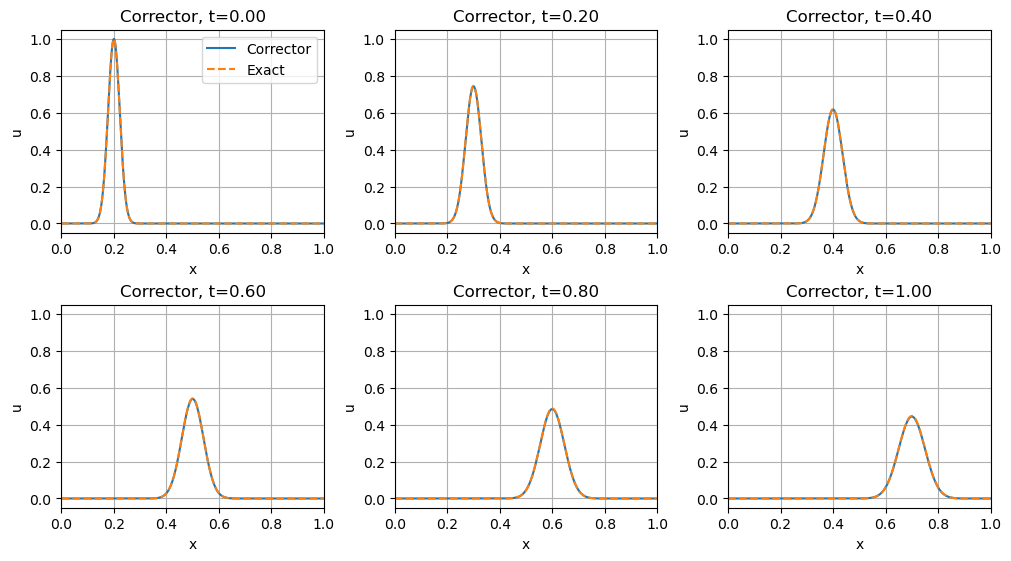

In [7]:
# Diagnostics
fig_times = [0, .2, .4, .6, .8, 1.0]
fig, axes = plt.subplots(2, 3, figsize=(10, 5.5), constrained_layout=True)
for ax, tq in zip(axes.flat, fig_times):
    ir = np.argmin(np.abs(plot_times - tq))
    ax.plot(x_plot, Uplot[ir], label="Corrector")
    ax.plot(x_plot, uexact(x_plot, plot_times[ir]), "--", label="Exact")
    ax.set(xlim=(XL, XR), ylim=(-0.05, 1.05), xlabel="x", ylabel="u",
           title=f"Corrector, t={plot_times[ir]:.2f}")
    ax.grid(True)
axes.flat[0].legend()
plt.show()